In [10]:
import pandas as pd
import numpy as np
import os 
import glob

data_path= "/Users/zhaliedingding/output/AG_atlas_human_SCN1A_RNAseq/P1b_AG_atlas_human_SCN1A_RNAseq"

In [26]:
raw_lfc=pd.read_csv(data_path + "/raw_scores.csv",index_col=0) # loading the data path
tracks=pd.read_csv(data_path + "/tracks.csv",index_col=0)
var=pd.read_csv(data_path + "/variants_and_genes.csv",index_col=0)

In [25]:
raw_lfc

,0,1,2,3,4,5,6,7,8,9,...,361,362,363,364,365,366,367,368,369,370
0,-0.082681,0.019330,0.001119,0.000635,-0.033356,-0.001876,0.005616,-0.007730,-0.004667,-0.047071,...,-0.002277,0.032693,0.034371,0.017128,0.000623,-0.051190,-0.052814,-0.052663,-0.053013,0.007552
1,0.076525,-0.015312,-0.001511,-0.000603,0.045253,0.001574,0.003197,0.007419,0.006982,0.053691,...,-0.015618,-0.027685,-0.015162,-0.024377,0.012477,0.017846,0.015974,0.017180,0.015954,-0.021154
2,-0.225946,-0.035706,0.006250,0.002077,-0.168942,-0.039402,-0.082183,-0.096890,-0.078314,-0.165197,...,-0.059474,-0.097145,-0.013523,-0.096204,0.020750,-0.197815,-0.200018,-0.201676,-0.200902,-0.056924
3,-0.027146,-0.020805,0.001744,0.000598,-0.037961,-0.013570,-0.035795,-0.028965,-0.023144,-0.035869,...,-0.001994,-0.046508,-0.002573,-0.052871,0.019358,-0.072277,-0.072206,-0.072862,-0.071582,-0.024849
4,-0.081211,0.022766,0.003669,0.001513,-0.054601,0.000777,-0.008153,-0.013530,-0.005201,-0.059429,...,-0.024501,-0.024033,0.016080,-0.028654,0.020694,-0.075517,-0.076283,-0.077440,-0.075514,-0.010400
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5005,-0.001945,-0.002366,-0.000133,-0.000122,0.000570,-0.001683,-0.002679,-0.003119,-0.003260,-0.002614,...,-0.001165,0.000945,0.000638,-0.002435,0.001328,-0.004498,-0.004523,-0.004762,-0.004470,-0.000955
5006,-0.005230,0.000460,0.000371,0.000177,-0.002546,-0.000242,-0.001657,-0.001031,-0.000504,-0.003544,...,0.000340,0.000668,0.002406,-0.000711,0.001206,-0.004462,-0.004297,-0.004553,-0.003901,0.000628
5007,-0.004646,0.002186,0.000117,0.000048,-0.003427,0.000003,-0.000326,-0.001726,-0.001124,-0.004695,...,0.000562,0.002657,0.001275,-0.000424,0.001221,-0.008153,-0.008141,-0.008445,-0.008464,0.001065
5008,0.000714,0.001915,-0.000028,-0.000064,0.002373,0.000740,0.001356,0.000031,-0.000173,-0.001521,...,-0.000533,-0.000733,-0.001868,-0.002868,0.001533,-0.005164,-0.005191,-0.005474,-0.005108,-0.001535


In [27]:
tracks


,name,strand,Assay title,ontology_curie,biosample_name,biosample_type,biosample_life_stage,gtex_tissue,data_source,endedness,genetically_modified,nonzero_mean
0,CL:0000047 polyA plus RNA-seq,.,polyA plus RNA-seq,CL:0000047,neuronal stem cell,in_vitro_differentiated_cells,embryonic,NaN,encode,paired,False,0.143617
1,CL:0000062 total RNA-seq,.,total RNA-seq,CL:0000062,osteoblast,primary_cell,adult,NaN,encode,paired,False,0.094144
2,CL:0000084 polyA plus RNA-seq,.,polyA plus RNA-seq,CL:0000084,T-cell,primary_cell,adult,NaN,encode,paired,False,0.124296
3,CL:0000084 total RNA-seq,.,total RNA-seq,CL:0000084,T-cell,primary_cell,adult,NaN,encode,single,False,0.100934
4,CL:0000115 total RNA-seq,.,total RNA-seq,CL:0000115,endothelial cell,in_vitro_differentiated_cells,adult,NaN,encode,single,False,0.135553
...,...,...,...,...,...,...,...,...,...,...,...,...
366,UBERON:0018115 polyA plus RNA-seq,.,polyA plus RNA-seq,UBERON:0018115,left renal pelvis,tissue,embryonic,NaN,encode,single,False,0.268222
367,UBERON:0018116 polyA plus RNA-seq,.,polyA plus RNA-seq,UBERON:0018116,right renal pelvis,tissue,embryonic,NaN,encode,single,False,0.258522
368,UBERON:0018117 polyA plus RNA-seq,.,polyA plus RNA-seq,UBERON:0018117,left renal cortex interstitium,tissue,embryonic,NaN,encode,single,False,0.215190
369,UBERON:0018118 polyA plus RNA-seq,.,polyA plus RNA-seq,UBERON:0018118,right renal cortex interstitium,tissue,embryonic,NaN,encode,single,False,0.365676


In [28]:
var

,gene_id,gene_name,strand,variant,interval
0,ENSG00000144285.24,SCN1A,-,chr2:166127425:A>C,chr2:165601280-166649856:.
1,ENSG00000144285.24,SCN1A,-,chr2:166127425:A>G,chr2:165601280-166649856:.
2,ENSG00000144285.24,SCN1A,-,chr2:166127425:A>T,chr2:165601280-166649856:.
3,ENSG00000144285.24,SCN1A,-,chr2:166127426:G>A,chr2:165601280-166649856:.
4,ENSG00000144285.24,SCN1A,-,chr2:166127426:G>C,chr2:165601280-166649856:.
...,...,...,...,...,...
5005,ENSG00000144285.24,SCN1A,-,chr2:166129023:C>G,chr2:165601280-166649856:.
5006,ENSG00000144285.24,SCN1A,-,chr2:166129023:C>T,chr2:165601280-166649856:.
5007,ENSG00000144285.24,SCN1A,-,chr2:166129024:A>C,chr2:165601280-166649856:.
5008,ENSG00000144285.24,SCN1A,-,chr2:166129024:A>G,chr2:165601280-166649856:.


In [29]:
raw_lfc.shape

(5010, 371)

In [35]:
from matplotlib import pyplot as plt

In [38]:
raw_lcp_array=np.ravel(raw_lfc.values)

In [50]:
plt.hist(raw_lcp_array), bins=1000)
plt.show()

SyntaxError: unmatched ')' (490298584.py, line 1)

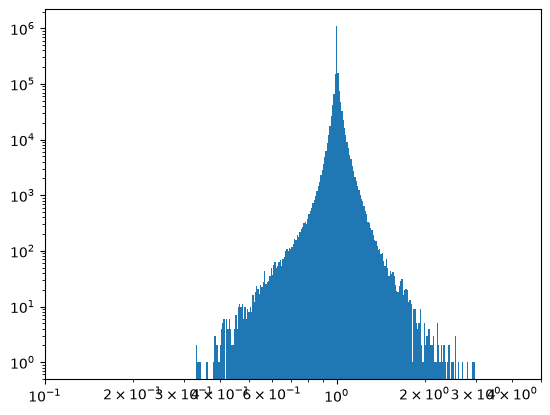

In [68]:
plt.hist(np.exp(raw_lcp_array), bins=np.geomspace(0.0001,3, 1000))
plt.xlim(0.1, 5)
plt.yscale('log')
plt.xscale('log')
plt.show()

In [60]:
np.geomspace(0.0001,3, 100)

array([1.00000000e-04, 1.10974564e-04, 1.23153538e-04, 1.36669102e-04,
       1.51667940e-04, 1.68312835e-04, 1.86784435e-04, 2.07283212e-04,
       2.30031640e-04, 2.55276610e-04, 2.83292104e-04, 3.14382177e-04,
       3.48884250e-04, 3.87172775e-04, 4.29663299e-04, 4.76816972e-04,
       5.29145555e-04, 5.87216972e-04, 6.51661474e-04, 7.23178479e-04,
       8.02544163e-04, 8.90619885e-04, 9.88361533e-04, 1.09682990e-03,
       1.21720220e-03, 1.35078483e-03, 1.49902758e-03, 1.66353932e-03,
       1.84610550e-03, 2.04870753e-03, 2.27354425e-03, 2.52305581e-03,
       2.79995018e-03, 3.10723251e-03, 3.44823772e-03, 3.82666677e-03,
       4.24662676e-03, 4.71267553e-03, 5.22987112e-03, 5.80382667e-03,
       6.44077133e-03, 7.14761790e-03, 7.93203779e-03, 8.80254435e-03,
       9.76858520e-03, 1.08406448e-02, 1.20303583e-02, 1.33506377e-02,
       1.48158119e-02, 1.64417827e-02, 1.82461966e-02, 2.02486371e-02,
       2.24708368e-02, 2.49369131e-02, 2.76736306e-02, 3.07106908e-02,
      

In [55]:
np.min(np.exp(raw_lcp_array))
np.max(np.exp(raw_lcp_array))

np.float64(3.1704007517206723)

In [9]:
! ls /Users/zhaliedingding/output/AG_atlas_human_SCN1A_RNAseq/P1b_AG_atlas_human_SCN1A_RNAseq/raw_scores.csv         

quantile_scores.csv    tracks.csv
raw_scores.csv         variants_and_genes.csv


In [5]:
! pwd

/Users/zhaliedingding/git/ML_SCN1A/ag_aaron/AG atlas RNAseq data acquisition
